# Generating training data

Using the Gilmore-Akulichev model to generate training data at a range of frequencies and intensities

In [2]:
import sys
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt

from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
def generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure):
    # generate sound wave

    BD_obj = BD(R_init, Rdot_init, frequency, pac, time, tstep)
    BD_obj.solver()
    BD_obj.calculate_p_radiated(r_measure=r_measure)

    data = BD_obj.p_radiated
    time = BD_obj.time

    return data

In [4]:
frequency = 1E5
pac = -10E5

no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 3
mode = "zero"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

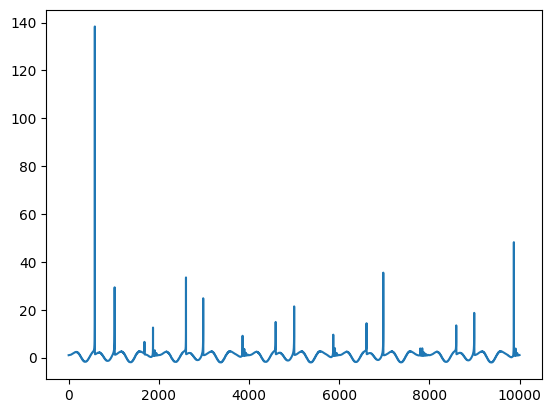

In [18]:
data = generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
plt.plot(data[::10])
plt.show()

In [ ]:
tr_obj = wpt.dwpt(data, levels, wavelet, mode)